In [210]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Wizualizacje na spotkanie z promotorem

1. Struktura mocy zainstalowanej (baza bloków)
2. Prognozy zapotrzebowania, wiatru i PV w wybranym okresie
3. Wymiana: maxBex (limity flow-based) i planowana wymiana handlowa
4. Ceny DA – punkt odniesienia do porównania z modelem
5. Kontrola danych

# Wczytanie danych

Duże pliki wczytuję tylko z potrzebnymi kolumnami (`usecols=`), żeby oszczędzić pamięć.

In [211]:
units = pd.read_csv("../data/bloki_PL_DE_CZ_SK_LT_SE.csv")
prices = pd.read_csv("../data/price_actual.csv", usecols=["zone", "delivery_start", "price"])
load_fcst = pd.read_csv("../data/prognoza_load.csv", usecols=["start_date", "zone", "value", "run_date", "published_at"])
gen_fcst = pd.read_csv("../data/prognoza_gen.csv", usecols=["start_date", "zone", "value", "fuel_type", "run_date", "published_at"])
exchange = pd.read_csv("../data/links/sce.csv", usecols=["start_date", "zone_from", "zone_to", "value"])
core_bex_raw = pd.read_csv("../data/323d9994-dc99-4910-9b23-bd83ea9c7b00.csv", usecols=["datetime_utc", "extra_json"])
nordic_bex_raw = pd.read_csv("../data/links/nordic_max_bex.csv", usecols=["datetime_utc", "extra_json"])

In [ ]:
# time: UTC without timezone in the object
prices["time"] = pd.to_datetime(prices["delivery_start"], utc=True).dt.tz_localize(None)
load_fcst["time"] = pd.to_datetime(load_fcst["start_date"], utc=True).dt.tz_localize(None)
gen_fcst["time"] = pd.to_datetime(gen_fcst["start_date"], utc=True).dt.tz_localize(None)
exchange["time"] = pd.to_datetime(exchange["start_date"], utc=True).dt.tz_localize(None)
core_bex_raw["time"] = pd.to_datetime(core_bex_raw["datetime_utc"], utc=True).dt.tz_localize(None)
nordic_bex_raw["time"] = pd.to_datetime(nordic_bex_raw["datetime_utc"], utc=True).dt.tz_localize(None)

load_fcst.head()

,start_date,zone,value,run_date,published_at,time
0,2025-01-02 00:00:00.000,PL,14500.0,2025-01-01,2025-01-01 06:55:00.000,2025-01-02 00:00:00
1,2025-01-02 00:00:00.000,DE,45572.0,2025-01-01,2025-01-01 06:55:00.000,2025-01-02 00:00:00
2,2025-01-02 00:00:00.000,CZ,6100.0,2025-01-01,2025-01-01 06:55:00.000,2025-01-02 00:00:00
3,2025-01-02 00:15:00.000,DE,45572.0,2025-01-01,2025-01-01 06:55:00.000,2025-01-02 00:15:00
4,2025-01-02 00:15:00.000,PL,14500.0,2025-01-01,2025-01-01 06:55:00.000,2025-01-02 00:15:00


Niemcy: w prognozie zapotrzebowania strefa nazywa się `DE`, a w cenach, prognozie OZE i wymianie `DE-LU`.
Ujednolicam wszędzie na `DE`.

In [213]:
# same name for Germany in all files
prices["zone"] = prices["zone"].replace("DE-LU", "DE")
gen_fcst["zone"] = gen_fcst["zone"].replace("DE-LU", "DE")
exchange["zone_from"] = exchange["zone_from"].replace("DE-LU", "DE")
exchange["zone_to"] = exchange["zone_to"].replace("DE-LU", "DE")

print(sorted(prices["zone"].unique()))
print(sorted(load_fcst["zone"].unique()))
print(sorted(gen_fcst["zone"].unique()))

['CZ', 'DE', 'LT', 'PL', 'SE1', 'SE2', 'SE3', 'SE4', 'SK']
['CZ', 'DE', 'LT', 'PL', 'SE1', 'SE2', 'SE3', 'SE4', 'SK']
['CZ', 'DE', 'LT', 'PL', 'SE1', 'SE2', 'SE3', 'SE4', 'SK']


In [214]:
# zone order used on all charts
zones = ["PL", "DE", "CZ", "SK", "LT", "SE1", "SE2", "SE3", "SE4"]

# 1. Struktura mocy zainstalowanej

Szczegółowe rodzaje paliw grupuję w kilka większych grup, żeby wykres był czytelny.
Bloki DE w rezerwie sieciowej odfiltrowuję, bo nie biorą udziału w rynku DA.

In [215]:
fuel_groups = {
    "węgiel kamienny": "hard coal",
    "węgiel brunatny": "lignite",
    "jądrowe (uran)": "nuclear",
    "gaz – CCGT": "gas",
    "gaz – OCGT": "gas",
    "gaz – blok parowy (kocioł gazowy)": "gas",
    "gaz – silnik tłokowy": "gas",
    "gaz – technologia nieokreślona": "gas",
    "olej": "oil",
    "biomasa stała": "biomass",
    "biomasa – biogaz": "biomass",
    "woda – przepływowa": "hydro",
    "woda – zbiornikowa": "hydro",
    "woda – typ nieokreślony": "hydro",
    "magazyn – elektrownia szczytowo-pompowa": "pumped storage",
    "magazyn – bateria": "battery",
}

units["fuel group"] = units["rodzaj paliwa"].map(fuel_groups)

# units without a group (should be 0)
print("without group:", units["fuel group"].isna().sum())

without group: 0


In [216]:
grid_reserve = units["nazwa bloku"].str.contains("rezerwa sieciowa")
print("units in grid reserve:", grid_reserve.sum())

market_units = units[~grid_reserve]
market_units.shape

units in grid reserve: 28


(3881, 9)

In [217]:
capacity = market_units.groupby(["kod kraju", "fuel group"])["moc zainstalowana [MW]"].sum().reset_index()
capacity_table = capacity.pivot(index="kod kraju", columns="fuel group", values="moc zainstalowana [MW]")
capacity_table = capacity_table.fillna(0) / 1000  # MW -> GW

fuel_order = ["nuclear", "lignite", "hard coal", "gas", "oil", "biomass", "hydro", "pumped storage", "battery"]
capacity_table = capacity_table[fuel_order]
capacity_table = capacity_table.loc[["PL", "DE", "CZ", "SK", "LT", "SE"]]
capacity_table.round(1)

fuel group,nuclear,lignite,hard coal,gas,oil,biomass,hydro,pumped storage,battery
kod kraju,,,,,,,,,
PL,0.0,7.5,18.4,5.1,0.4,0.7,0.4,1.8,0.2
DE,0.0,14.0,7.0,31.6,5.4,9.1,3.7,7.2,22.0
CZ,4.2,6.7,0.7,1.8,0.0,0.0,0.7,1.2,0.0
SK,2.9,0.0,0.3,1.1,0.0,0.0,1.5,1.0,0.0
LT,0.0,0.0,0.0,1.3,0.0,0.1,0.1,0.9,0.2
SE,7.2,0.0,0.0,0.8,2.7,3.2,15.2,0.1,0.8


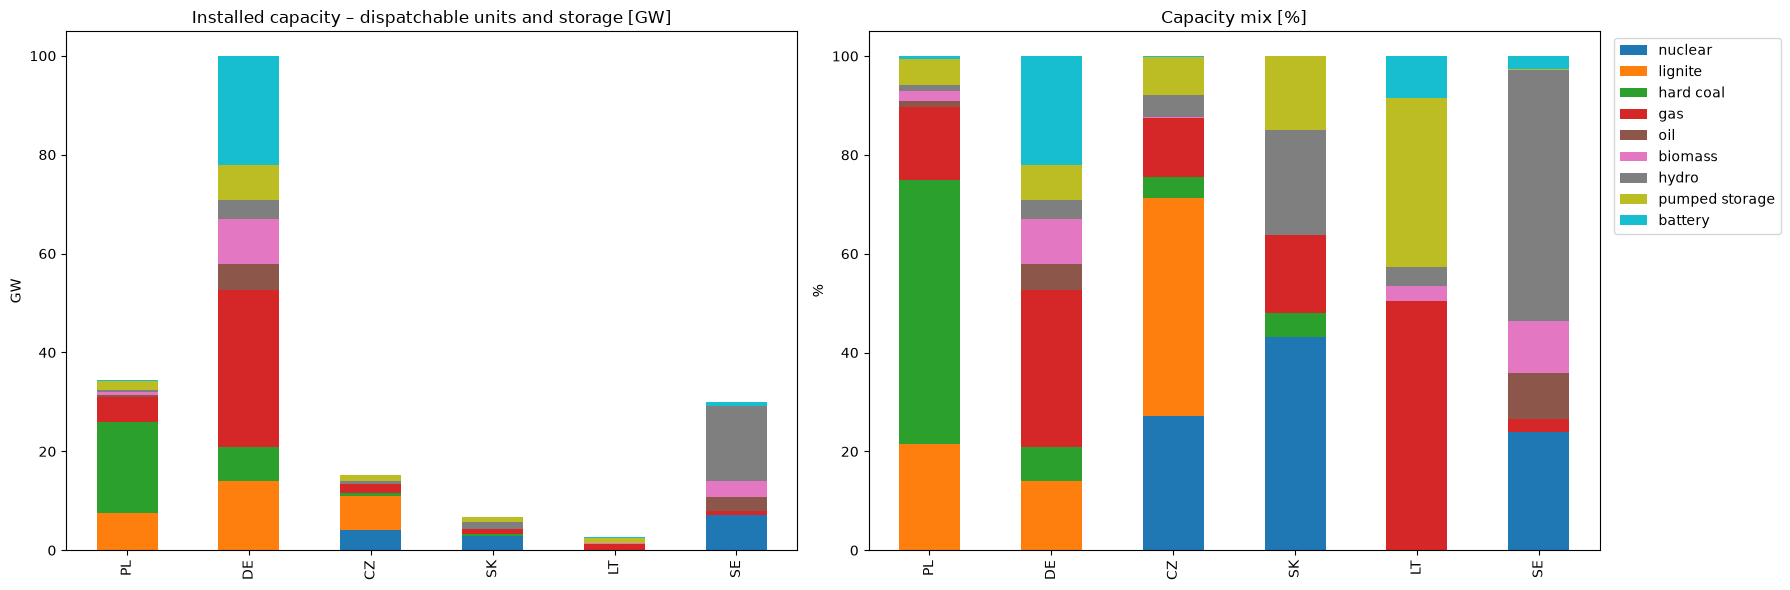

In [218]:
# percentage share of each fuel group in a country
share_table = capacity_table.div(capacity_table.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

capacity_table.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10", legend=False)
axes[0].set_title("Installed capacity – dispatchable units and storage [GW]")
axes[0].set_ylabel("GW")
axes[0].set_xlabel("")

share_table.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10")
axes[1].set_title("Capacity mix [%]")
axes[1].set_ylabel("%")
axes[1].set_xlabel("")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")

plt.tight_layout()
plt.show()

## Szczegółowo: każdy kraj osobno

Tu już bez grupowania – pełne kategorie z kolumny `rodzaj paliwa`. Każdy kraj ma własną skalę osi.

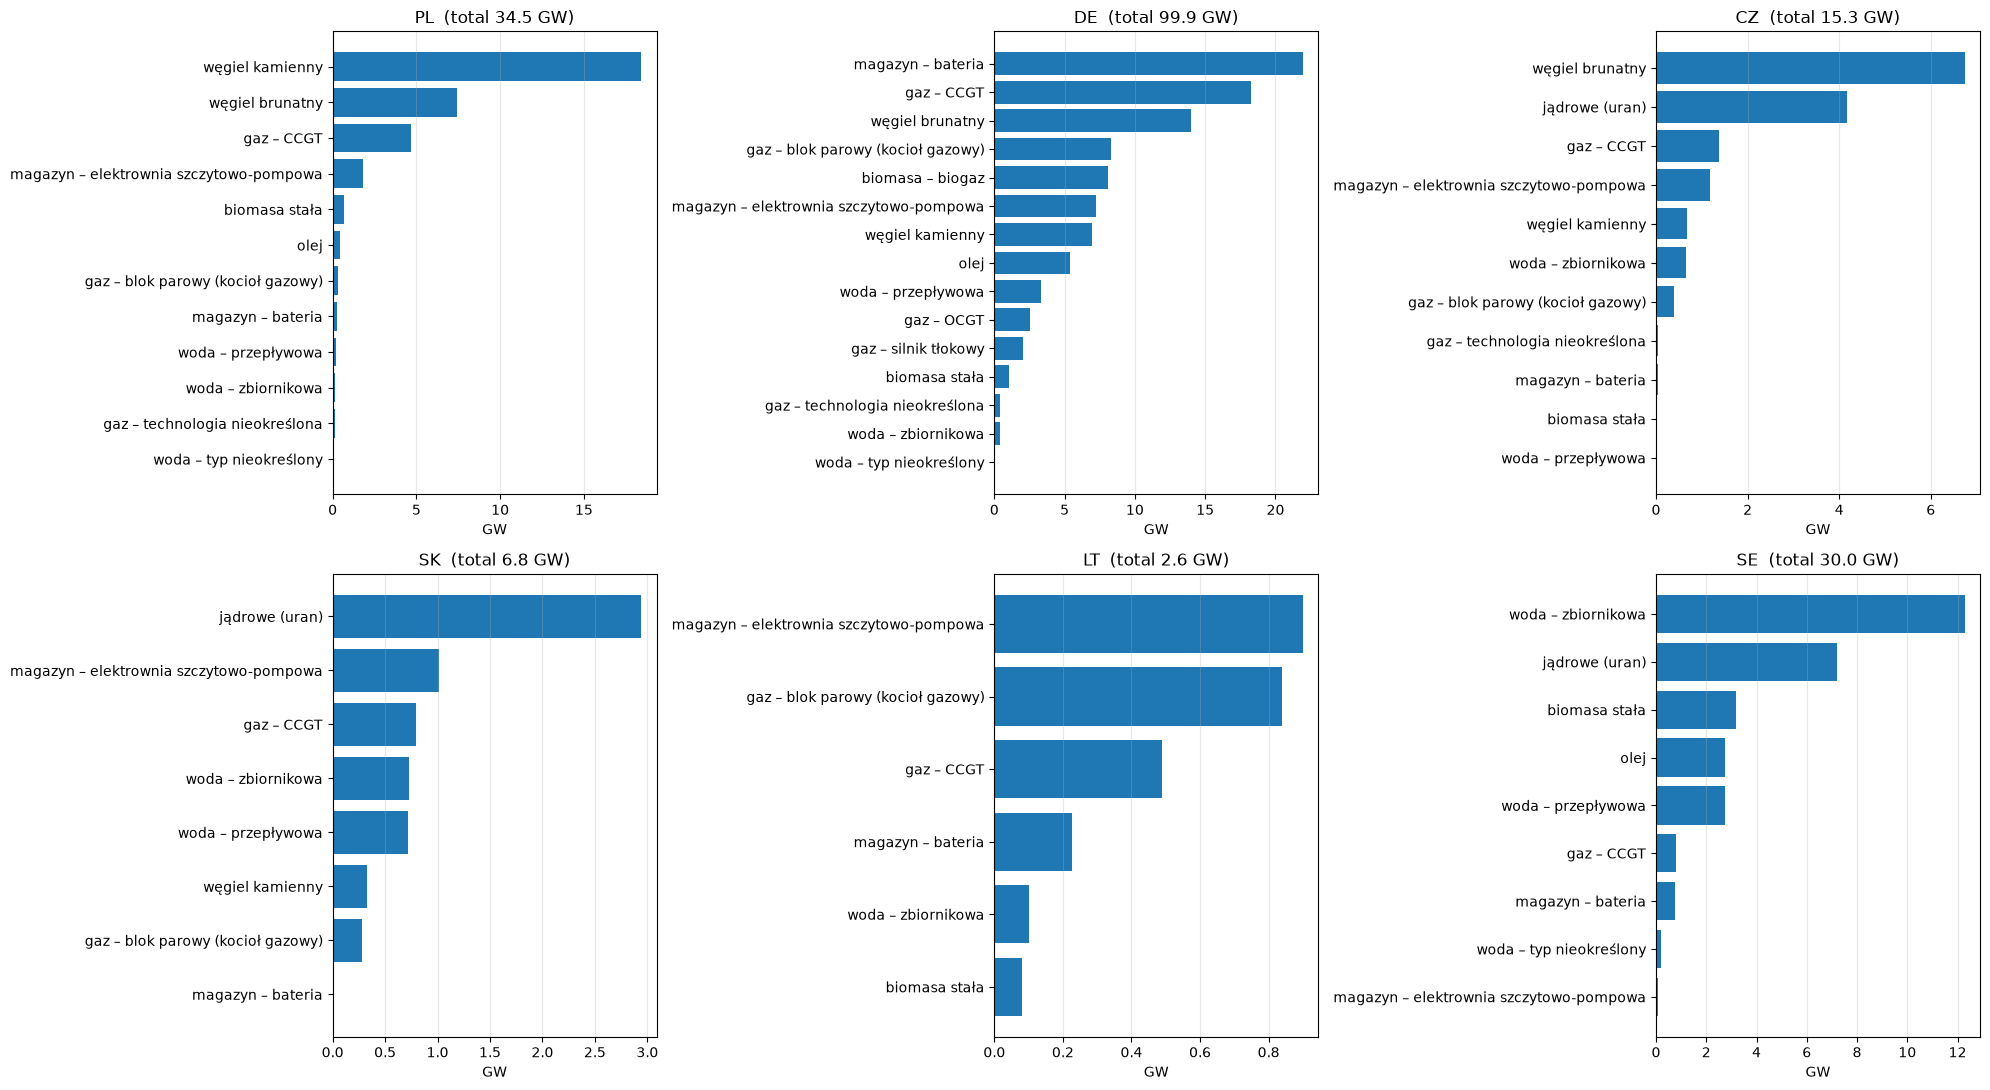

In [219]:
countries = ["PL", "DE", "CZ", "SK", "LT", "SE"]

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
axes = axes.flatten()  # 2x3 grid -> simple list of 6 axes

for i, country in enumerate(countries):
    country_units = market_units[market_units["kod kraju"] == country]
    country_capacity = country_units.groupby("rodzaj paliwa")["moc zainstalowana [MW]"].sum() / 1000
    country_capacity = country_capacity.sort_values()

    axes[i].barh(country_capacity.index, country_capacity.values, color="tab:blue")
    axes[i].set_title(country + "  (total " + str(round(country_capacity.sum(), 1)) + " GW)")
    axes[i].set_xlabel("GW")
    axes[i].grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.show()

**Co mówić:** baza ma tylko jednostki sterowalne i magazyny (wiatr i PV wchodzą do modelu jako prognozy, nie jako bloki).
Strefy mają różny charakter: PL na węglu, SE na wodzie i atomie, DE z dużym udziałem gazu i baterii.
To tłumaczy, dlaczego ceny w strefach się różnią.

# 2. Prognozy w wybranym okresie

Okres ustawiam w jednym miejscu – wystarczy zmienić daty i uruchomić komórki poniżej jeszcze raz.
Zapotrzebowanie rezydualne = zapotrzebowanie − wiatr − PV (to, co muszą pokryć elektrownie sterowalne).

In [220]:
period_start = "2025-06-02"
period_end = "2025-06-09"  # end date is not included

In [221]:
# one forecast per zone and time (in case a file has several runs)
load_fcst = load_fcst.drop_duplicates(subset=["time", "zone"])
gen_fcst = gen_fcst.drop_duplicates(subset=["time", "zone", "fuel_type"])

load_table = load_fcst.pivot(index="time", columns="zone", values="value")
wind_table = gen_fcst[gen_fcst["fuel_type"] == "wind"].pivot(index="time", columns="zone", values="value")
solar_table = gen_fcst[gen_fcst["fuel_type"] == "solar"].pivot(index="time", columns="zone", values="value")

load_period = load_table[(load_table.index >= period_start) & (load_table.index < period_end)]
wind_period = wind_table[(wind_table.index >= period_start) & (wind_table.index < period_end)]
solar_period = solar_table[(solar_table.index >= period_start) & (solar_table.index < period_end)]

load_period.shape, wind_period.shape, solar_period.shape

((672, 9), (672, 8), (672, 9))

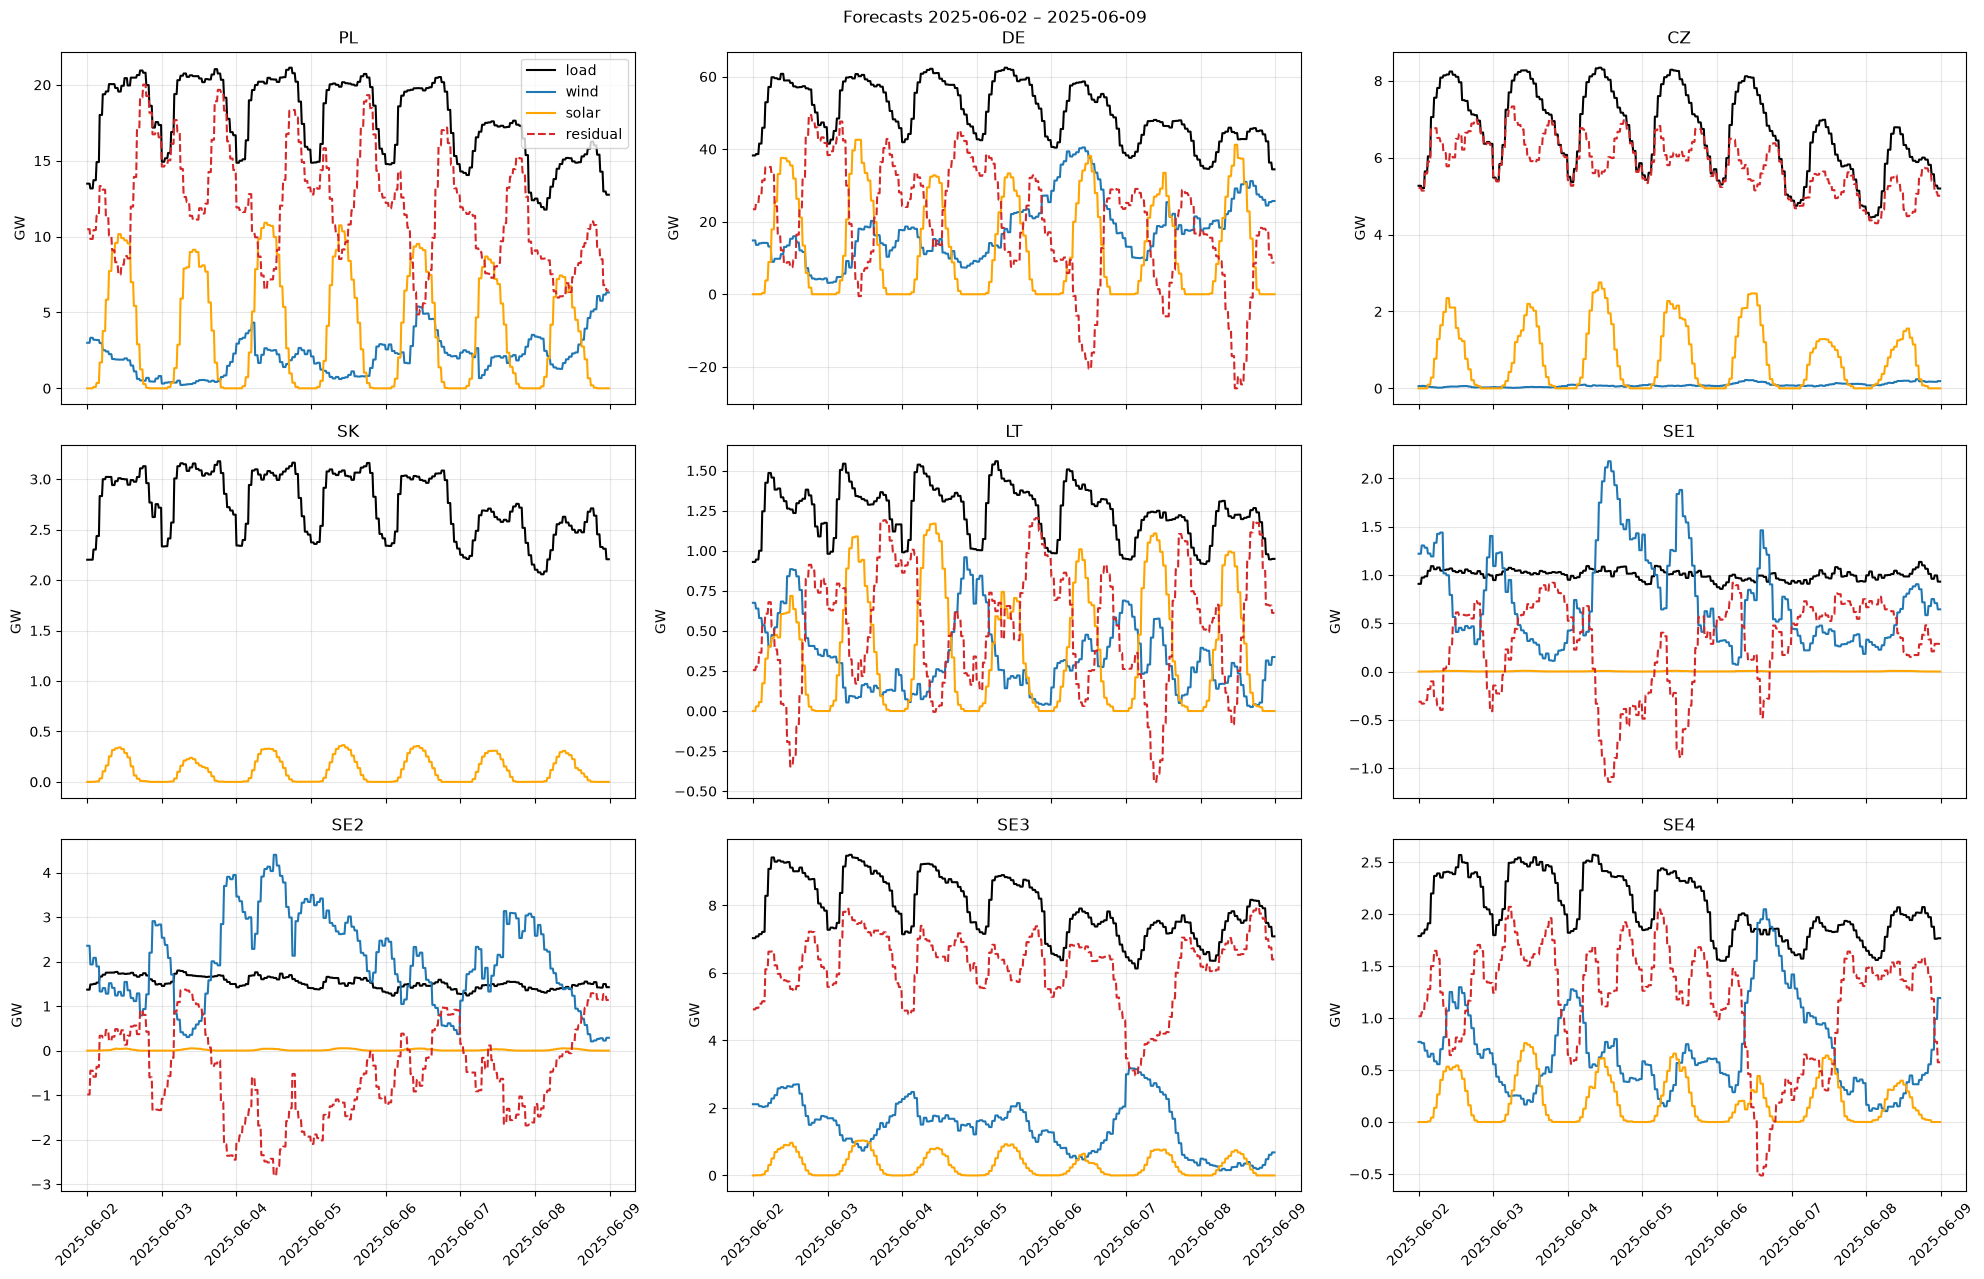

In [222]:
fig, axes = plt.subplots(3, 3, figsize=(20, 13), sharex=True)
axes = axes.flatten()

for i, zone in enumerate(zones):
    ax = axes[i]

    # a forecast can be missing for some zones (e.g. wind SK)
    if zone in load_period.columns:
        ax.plot(load_period.index, load_period[zone] / 1000, label="load", color="black")
    if zone in wind_period.columns:
        ax.plot(wind_period.index, wind_period[zone] / 1000, label="wind", color="tab:blue")
    if zone in solar_period.columns:
        ax.plot(solar_period.index, solar_period[zone] / 1000, label="solar", color="orange")

    # residual load only when all three forecasts exist
    if zone in load_period.columns and zone in wind_period.columns and zone in solar_period.columns:
        residual = load_period[zone] - wind_period[zone] - solar_period[zone]
        ax.plot(residual.index, residual / 1000, label="residual", color="tab:red", linestyle="--")

    ax.set_title(zone)
    ax.set_ylabel("GW")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

axes[0].legend()
plt.suptitle("Forecasts " + period_start + " – " + period_end)
plt.tight_layout()
plt.show()

## Średnie wartości prognoz w strefach (cały okres danych)

In [223]:
mean_forecasts = pd.DataFrame({
    "load": load_table.mean(),
    "wind": wind_table.mean(),
    "solar": solar_table.mean(),
}) / 1000  # MW -> GW
mean_forecasts = mean_forecasts.loc[zones]
mean_forecasts.round(2)

,load,wind,solar
zone,,,
PL,18.42,2.50,2.64
DE,53.39,15.39,9.91
CZ,7.17,0.07,0.60
SK,2.92,NaN,0.08
LT,1.37,0.47,0.25
SE1,1.20,0.83,0.00
SE2,1.68,2.01,0.01
SE3,9.27,1.24,0.21
SE4,2.41,0.64,0.12


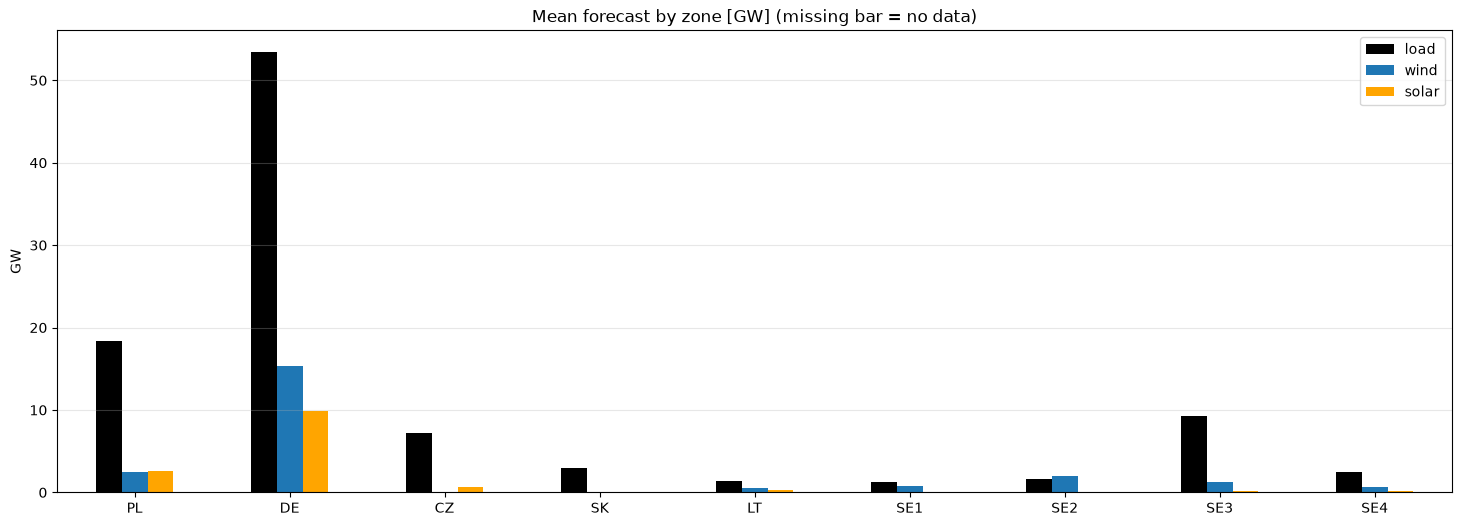

In [224]:
mean_forecasts.plot(kind="bar", figsize=(18, 6), color=["black", "tab:blue", "orange"])
plt.title("Mean forecast by zone [GW] (missing bar = no data)")
plt.ylabel("GW")
plt.xlabel("")
plt.xticks(rotation=0)
plt.grid(alpha=0.3, axis="y")
plt.show()

**Co mówić:** to są główne zmienne wejściowe modelu w każdej godzinie. Widać dobowy cykl PV
i to, jak mocno OZE „zjada” zapotrzebowanie w południe. Brak: wiatr SK.

# 3. Wymiana: maxBex i planowana wymiana handlowa

**maxBex** = maksymalna wymiana dwustronna między strefami, jaką dopuszcza domena flow-based
(CORE: PL, DE, CZ, SK; Nordic: SE i łącza z SE4). Do modelu NTC to naturalny kandydat na limit przesyłu.

Wartości są zapisane w kolumnie `extra_json` jako tekst JSON. `json.loads` zamienia tekst na słownik,
a `pd.json_normalize` robi z listy słowników tabelę (jedna kolumna na granicę).

In [225]:
core_bex = pd.json_normalize(core_bex_raw["extra_json"].map(json.loads))
core_bex["time"] = core_bex_raw["time"]

nordic_bex = pd.json_normalize(nordic_bex_raw["extra_json"].map(json.loads))
nordic_bex["time"] = nordic_bex_raw["time"]

# rows in the files are not in time order, which breaks line charts
core_bex = core_bex.sort_values("time")
nordic_bex = nordic_bex.sort_values("time")

core_bex.shape, nordic_bex.shape

((16008, 152), (44283, 65))

Granice, które są w modelu. Dla każdej: z którego pliku, kolumna kierunku A→B i B→A.
Granica PL–LT jest w pliku CORE jako wirtualny hub `PL_LT_BigHub` (LitPol w CORE przez advanced hybrid coupling):
`border_PL_PL_LT_BigHub` = PL→LT, `border_PL_LT_BigHub_PL` = LT→PL. Dane są dopiero od 10.06.2026 i mają stałe 250 MW,
więc na wykresie przebiegu dla 2025 to pole będzie puste.

In [226]:
borders = {
    "PL – DE": ["core", "border_PL_DE", "border_DE_PL", "PL", "DE"],
    "PL – CZ": ["core", "border_PL_CZ", "border_CZ_PL", "PL", "CZ"],
    "PL – SK": ["core", "border_PL_SK", "border_SK_PL", "PL", "SK"],
    "PL – LT": ["core", "border_PL_PL_LT_BigHub", "border_PL_LT_BigHub_PL", "PL", "LT"],
    "CZ – DE": ["core", "border_CZ_DE", "border_DE_CZ", "CZ", "DE"],
    "CZ – SK": ["core", "border_CZ_SK", "border_SK_CZ", "CZ", "SK"],
    "SE4 – PL": ["nordic", "border_SE4_PL", "border_PL_SE4", "SE4", "PL"],
    "SE4 – LT": ["nordic", "border_SE4_LT", "border_LT_SE4", "SE4", "LT"],
    "SE4 – DE": ["nordic", "border_SE4_DE", "border_DE_SE4", "SE4", "DE"],
    "SE1 – SE2": ["nordic", "border_SE1_SE2", "border_SE2_SE1", "SE1", "SE2"],
    "SE2 – SE3": ["nordic", "border_SE2_SE3", "border_SE3_SE2", "SE2", "SE3"],
    "SE3 – SE4": ["nordic", "border_SE3_SE4", "border_SE4_SE3", "SE3", "SE4"],
}

bex_files = {"core": core_bex, "nordic": nordic_bex}

In [227]:
# Nordic values are stored as text ("600.0000000000"), so convert them to numbers
for name, info in borders.items():
    bex = bex_files[info[0]]
    bex[info[1]] = pd.to_numeric(bex[info[1]])
    bex[info[2]] = pd.to_numeric(bex[info[2]])

nordic_bex[["time", "border_SE4_PL", "border_PL_SE4"]].head()

,time,border_SE4_PL,border_PL_SE4
0,2024-12-31 23:00:00,600.0,600.0
1,2025-01-01 00:00:00,600.0,600.0
2,2025-01-01 01:00:00,600.0,600.0
3,2025-01-01 02:00:00,600.0,600.0
4,2025-01-01 03:00:00,600.0,600.0


## Średni maxBex na granicach (cały okres)

In [228]:
mean_bex = []
for name, info in borders.items():
    bex = bex_files[info[0]]
    mean_bex.append({
        "border": name,
        "A -> B": bex[info[1]].mean(),
        "B -> A": bex[info[2]].mean(),
    })

mean_bex = pd.DataFrame(mean_bex).set_index("border")
mean_bex.round(0)

,A -> B,B -> A
border,,
PL – DE,4111.0,2881.0
PL – CZ,2716.0,4217.0
PL – SK,2604.0,3964.0
PL – LT,250.0,250.0
CZ – DE,5367.0,3551.0
CZ – SK,3093.0,4109.0
SE4 – PL,471.0,471.0
SE4 – LT,677.0,679.0
SE4 – DE,608.0,593.0


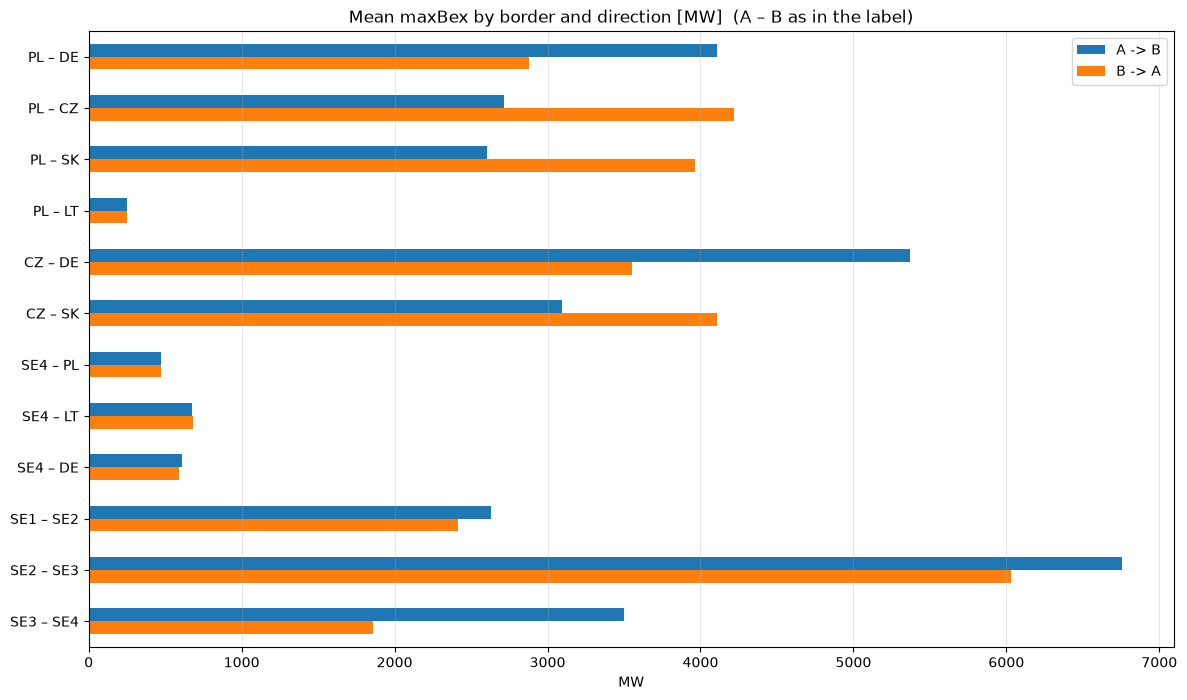

In [229]:
mean_bex.plot(kind="barh", figsize=(14, 8), color=["tab:blue", "tab:orange"])
plt.title("Mean maxBex by border and direction [MW]  (A – B as in the label)")
plt.xlabel("MW")
plt.ylabel("")
plt.gca().invert_yaxis()  # first border at the top
plt.grid(alpha=0.3, axis="x")
plt.show()

## Przebieg maxBex w wybranym okresie i planowana wymiana handlowa

Na każdym wykresie: kierunek A→B na plusie, B→A na minusie (szare pole = dopuszczalny zakres).
Czerwona linia = saldo planowanej wymiany handlowej DA z `sce.csv` (A→B minus B→A).
Gdy czerwona linia dotyka krawędzi szarego pola, połączenie jest zatkane i ceny stref się rozjeżdżają.
W `sce.csv` są tylko granice CORE, więc dla granic SE linii nie będzie.

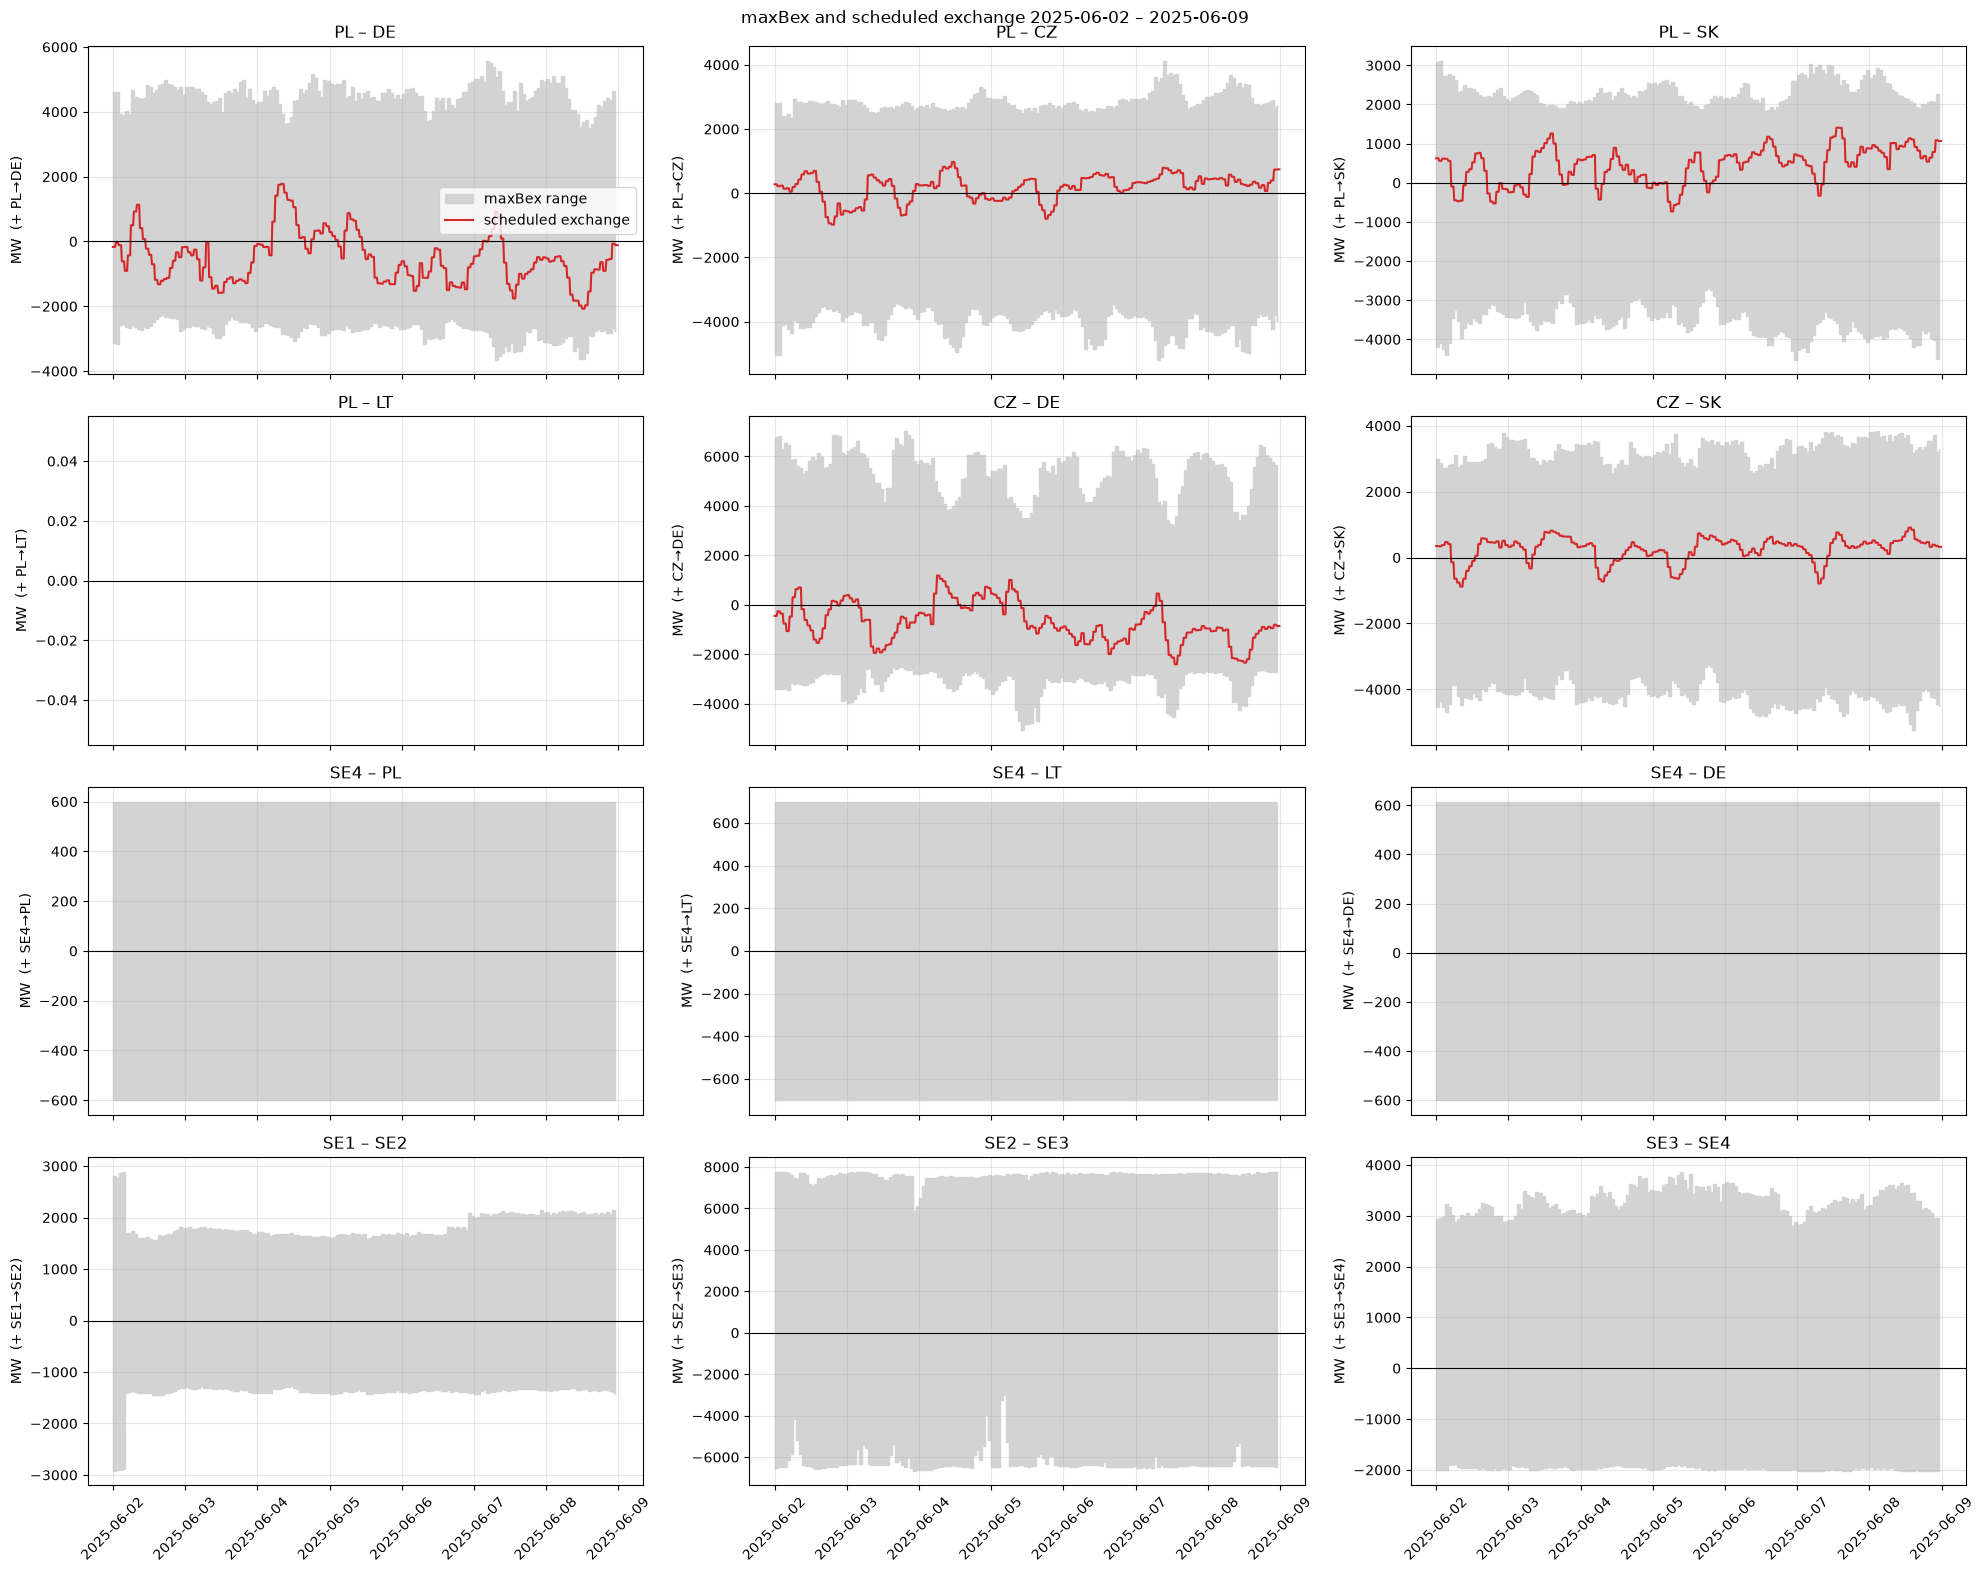

In [230]:
fig, axes = plt.subplots(4, 3, figsize=(20, 16), sharex=True)
axes = axes.flatten()

for i, (name, info) in enumerate(borders.items()):
    ax = axes[i]
    bex = bex_files[info[0]]
    bex_period = bex[(bex["time"] >= period_start) & (bex["time"] < period_end)]

    # maxBex: A -> B up, B -> A down
    ax.fill_between(bex_period["time"], bex_period[info[1]], -bex_period[info[2]], color="lightgray", step="post", label="maxBex range")

    # scheduled commercial exchange (net A -> B)
    zone_a = info[3]
    zone_b = info[4]
    flow_ab = exchange[(exchange["zone_from"] == zone_a) & (exchange["zone_to"] == zone_b)]
    flow_ba = exchange[(exchange["zone_from"] == zone_b) & (exchange["zone_to"] == zone_a)]
    if len(flow_ab) > 0 and len(flow_ba) > 0:
        flow_ab = flow_ab[["time", "value"]].rename(columns={"value": "ab"})
        flow_ba = flow_ba[["time", "value"]].rename(columns={"value": "ba"})
        net_flow = pd.merge(flow_ab, flow_ba, on="time")
        net_flow = net_flow[(net_flow["time"] >= period_start) & (net_flow["time"] < period_end)]
        net_flow = net_flow.sort_values("time")
        ax.plot(net_flow["time"], net_flow["ab"] - net_flow["ba"], color="tab:red", label="scheduled exchange")

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_ylabel("MW  (+ " + zone_a + "→" + zone_b + ")")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

axes[0].legend()
plt.suptitle("maxBex and scheduled exchange " + period_start + " – " + period_end)
plt.tight_layout()
plt.show()

## Statystyki planowanej wymiany handlowej (`sce.csv`)

Dla każdego kierunku (`zone_from` → `zone_to`) osobno, cały okres danych, w MW.
p95 = wartość, poniżej której jest 95% okresów; p99 analogicznie.

In [231]:
# a few timestamps are duplicated in the file
exchange_unique = exchange.drop_duplicates(subset=["time", "zone_from", "zone_to"])

exchange_grouped = exchange_unique.groupby(["zone_from", "zone_to"])["value"]

exchange_stats = pd.DataFrame({
    "mean": exchange_grouped.mean(),
    "median": exchange_grouped.median(),
    "p95": exchange_grouped.quantile(0.95),
    "p99": exchange_grouped.quantile(0.99),
    "max": exchange_grouped.max(),
})
exchange_stats.round(0)

mean  median     p95     p99     max
zone_from zone_to                                        
CZ        AT        928.0   894.0  2075.0  2427.0  8015.0
          DE        240.0     0.0  1328.0  1860.0  2704.0
          PL        139.0     0.0   718.0  1085.0  6489.0
          SK        474.0   500.0   972.0  1127.0  3625.0
DE        AT       1428.0  1390.0  3340.0  3928.0  7751.0
          BE        305.0     0.0  1000.0  1000.0  2000.0
          CH        616.0   799.0  1497.0  1850.0  2230.0
          CZ        636.0   520.0  1708.0  2012.0  6781.0
          FR       1392.0   652.0  4721.0  5376.0  5529.0
          NL        585.0     0.0  2592.0  3908.0  8825.0
          PL        557.0   460.0  1498.0  1736.0  5510.0
PL        CZ        270.0   159.0   878.0  1132.0  6617.0
          DE        304.0     0.0  1670.0  2367.0  3188.0
          SK        618.0   634.0  1328.0  1549.0  8269.0
          UA-IPS     82.0    25.0   333.0   378.0   495.0
SK        CZ         41.0     0.0   345.0   662.0  2097.0
          HU       1185.0  1224.0  2354.0  2707.0  8561.0
          PL         46.0     0.0   358.0   758.0  2261.0
          UA-IPS     84.0    30.0   337.0   423.0   441.0

**Co mówić:** maxBex zmienia się z godziny na godzinę (to wynik flow-based), więc stałe NTC to spore uproszczenie.
Do modelu można wziąć maxBex godzina po godzinie jako zmienny limit `Link` (`p_max_pu` w PyPSA).
Uwaga: maxBex pokazuje maksimum dla jednej granicy przy założeniu, że inne są puste – wszystkich naraz nie da się wykorzystać.
Uwaga 2: od 10.2025 w pliku CORE jest tylko jeden rekord na godzinę (mimo `mtu_minutes` = 15).

# 4. Ceny DA (punkt odniesienia do porównania z modelem)

## Średnie miesięczne ceny w strefach

In [232]:
prices["month"] = prices["time"].dt.to_period("M").dt.to_timestamp()

monthly_prices = prices.groupby(["month", "zone"])["price"].mean().reset_index()
monthly_prices = monthly_prices.pivot(index="month", columns="zone", values="price")
monthly_prices = monthly_prices[zones]
monthly_prices.round(1).head()

zone,PL,DE,CZ,SK,LT,SE1,SE2,SE3,SE4
month,,,,,,,,,
2025-01-01,117.8,117.9,130.6,142.5,92.2,21.1,21.6,56.8,68.2
2025-02-01,133.8,128.5,132.6,153.4,152.5,11.4,12.8,68.3,92.0
2025-03-01,99.3,94.7,99.9,103.8,92.2,14.4,10.0,46.3,55.1
2025-04-01,86.0,77.9,79.6,84.4,74.2,13.1,12.9,34.3,53.3
2025-05-01,94.0,67.3,73.1,77.2,67.6,12.9,13.8,39.4,55.0


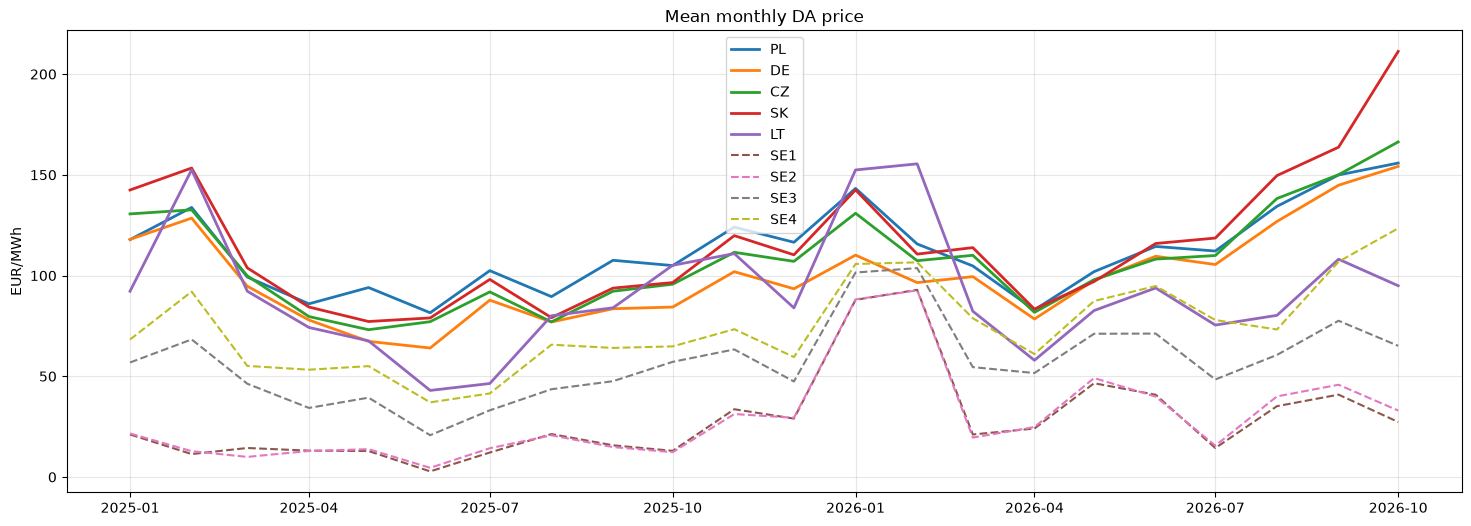

In [233]:
plt.figure(figsize=(18, 6))
for zone in zones:
    if zone in ["SE1", "SE2", "SE3", "SE4"]:
        plt.plot(monthly_prices.index, monthly_prices[zone], label=zone, linestyle="--")
    else:
        plt.plot(monthly_prices.index, monthly_prices[zone], label=zone, linewidth=2)
plt.title("Mean monthly DA price")
plt.ylabel("EUR/MWh")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Rozkład cen i ceny ujemne

In [234]:
# list of prices for each zone (for the boxplot)
price_lists = []
for zone in zones:
    price_lists.append(prices[prices["zone"] == zone]["price"])

# share of quarter-hours with price <= 0
negative_share = []
for zone in zones:
    zone_prices = prices[prices["zone"] == zone]["price"]
    negative_share.append((zone_prices <= 0).mean() * 100)

pd.DataFrame({"zone": zones, "share of price <= 0 [%]": negative_share}).round(1)

,zone,share of price <= 0 [%]
0,PL,4.6
1,DE,7.6
2,CZ,4.4
3,SK,4.2
4,LT,1.9
5,SE1,3.9
6,SE2,5.4
7,SE3,3.0
8,SE4,3.1


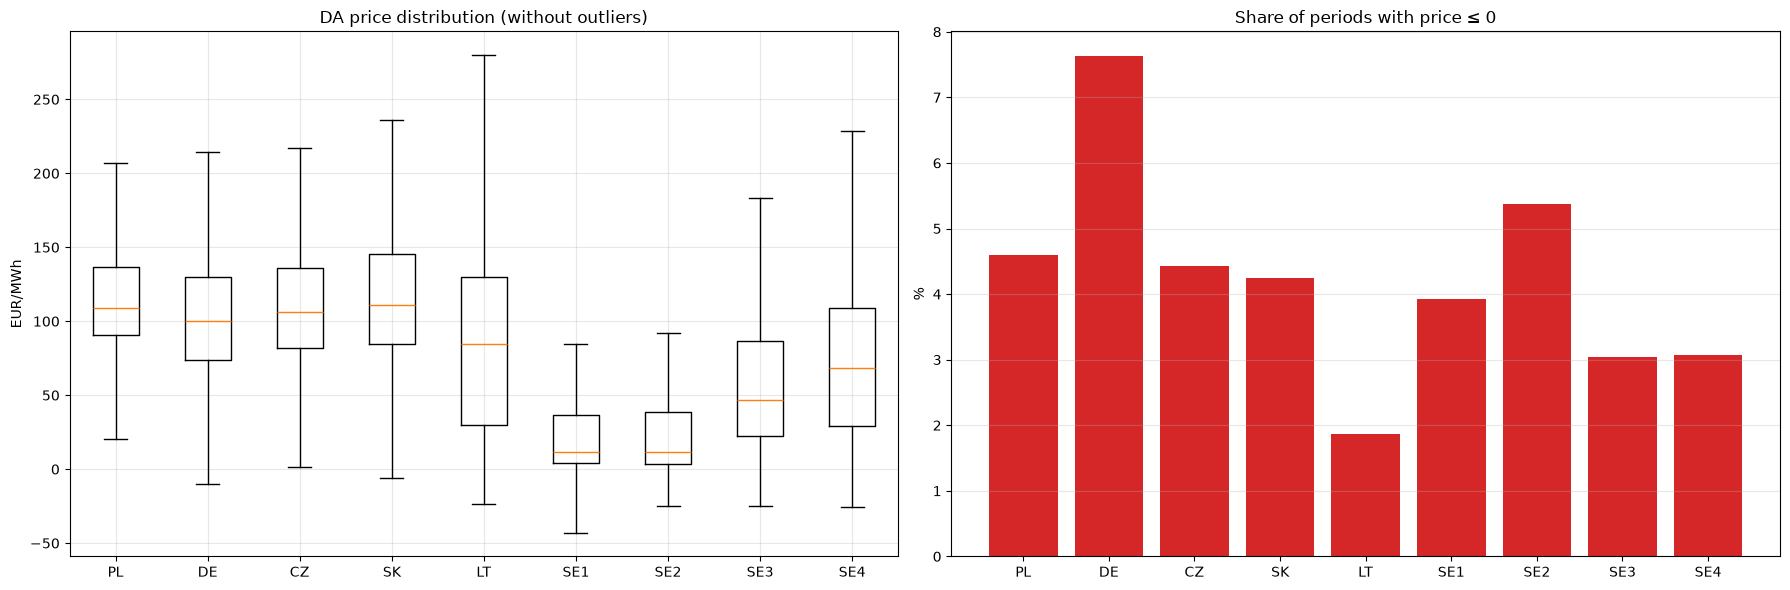

In [235]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].boxplot(price_lists, tick_labels=zones, showfliers=False)
axes[0].set_title("DA price distribution (without outliers)")
axes[0].set_ylabel("EUR/MWh")
axes[0].grid(alpha=0.3)

axes[1].bar(zones, negative_share, color="tab:red")
axes[1].set_title("Share of periods with price ≤ 0")
axes[1].set_ylabel("%")
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

**Co mówić:** model kosztowy (bez dopłat do OZE i strategii ofertowych) prawie nie da cen ≤ 0 – to będzie jedno ze źródeł błędu.

## Profil dobowy cen

Godziny w czasie lokalnym (Europe/Warsaw).

In [236]:
prices["local hour"] = prices["time"].dt.tz_localize("UTC").dt.tz_convert("Europe/Warsaw").dt.hour

daily_profile = prices.groupby(["local hour", "zone"])["price"].mean().reset_index()
daily_profile = daily_profile.pivot(index="local hour", columns="zone", values="price")
daily_profile = daily_profile[zones]
daily_profile.round(1).head()

zone,PL,DE,CZ,SK,LT,SE1,SE2,SE3,SE4
local hour,,,,,,,,,
0,112.0,104.5,108.5,118.0,77.4,21.2,21.9,46.6,65.6
1,106.9,98.9,103.9,110.6,68.6,20.2,20.9,43.2,60.8
2,103.7,95.5,100.7,107.2,64.5,19.8,20.6,41.5,58.0
3,103.0,94.1,99.3,105.3,63.8,19.8,20.6,41.0,56.9
4,104.2,95.2,100.5,107.0,68.2,20.6,21.3,42.1,58.0


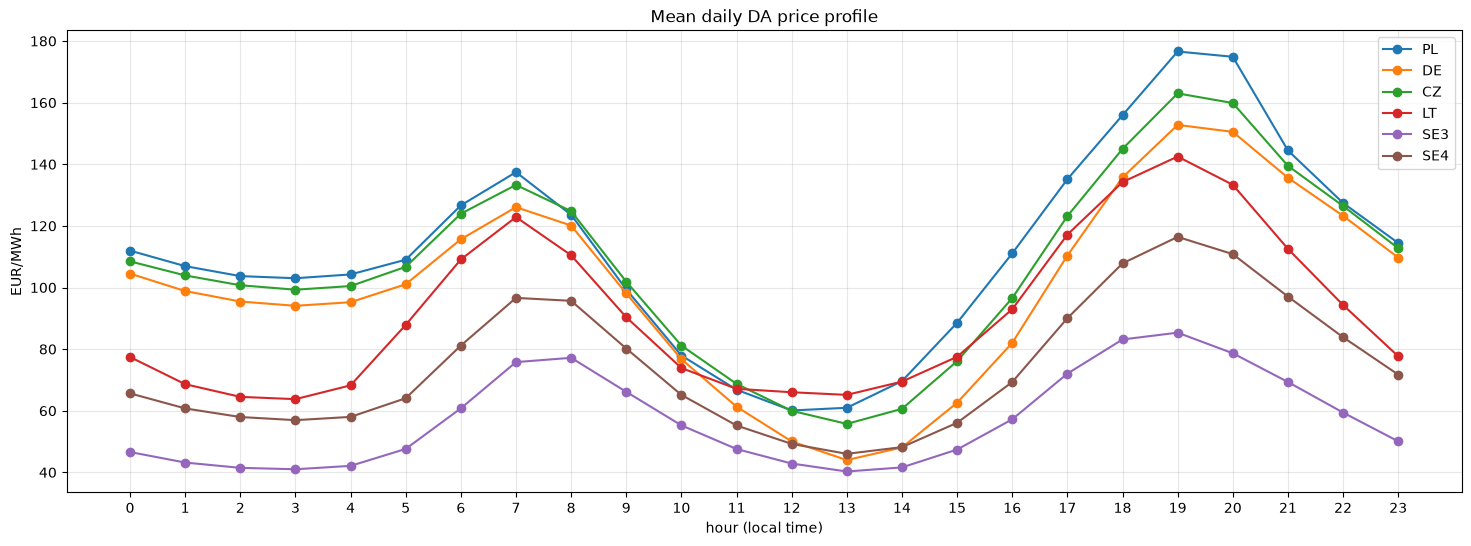

In [237]:
plt.figure(figsize=(18, 6))
for zone in ["PL", "DE", "CZ", "LT", "SE3", "SE4"]:
    plt.plot(daily_profile.index, daily_profile[zone], label=zone, marker="o")
plt.title("Mean daily DA price profile")
plt.xlabel("hour (local time)")
plt.ylabel("EUR/MWh")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Zbieżność cen między strefami

Dla każdej pary stref: w ilu procentach okresów ceny były prawie równe (różnica < 1 EUR/MWh).
Próg 1 EUR, a nie dokładna równość, bo przy flow-based ceny sąsiadów prawie nigdy nie są identyczne co do centa.

In [238]:
prices_wide = prices.pivot_table(index="time", columns="zone", values="price")
prices_wide = prices_wide[zones]

threshold = 1.0  # EUR/MWh
convergence = pd.DataFrame(index=zones, columns=zones, dtype=float)

for zone_a in zones:
    for zone_b in zones:
        difference = (prices_wide[zone_a] - prices_wide[zone_b]).abs()
        difference = difference.dropna()
        convergence.loc[zone_a, zone_b] = (difference < threshold).mean() * 100

convergence.round(0)

,PL,DE,CZ,SK,LT,SE1,SE2,SE3,SE4
PL,100.0,22.0,36.0,24.0,19.0,2.0,2.0,4.0,6.0
DE,22.0,100.0,29.0,23.0,11.0,3.0,4.0,6.0,13.0
CZ,36.0,29.0,100.0,40.0,13.0,2.0,3.0,4.0,7.0
SK,24.0,23.0,40.0,100.0,9.0,2.0,2.0,3.0,6.0
LT,19.0,11.0,13.0,9.0,100.0,15.0,14.0,20.0,35.0
SE1,2.0,3.0,2.0,2.0,15.0,100.0,44.0,18.0,16.0
SE2,2.0,4.0,3.0,2.0,14.0,44.0,100.0,23.0,20.0
SE3,4.0,6.0,4.0,3.0,20.0,18.0,23.0,100.0,31.0
SE4,6.0,13.0,7.0,6.0,35.0,16.0,20.0,31.0,100.0


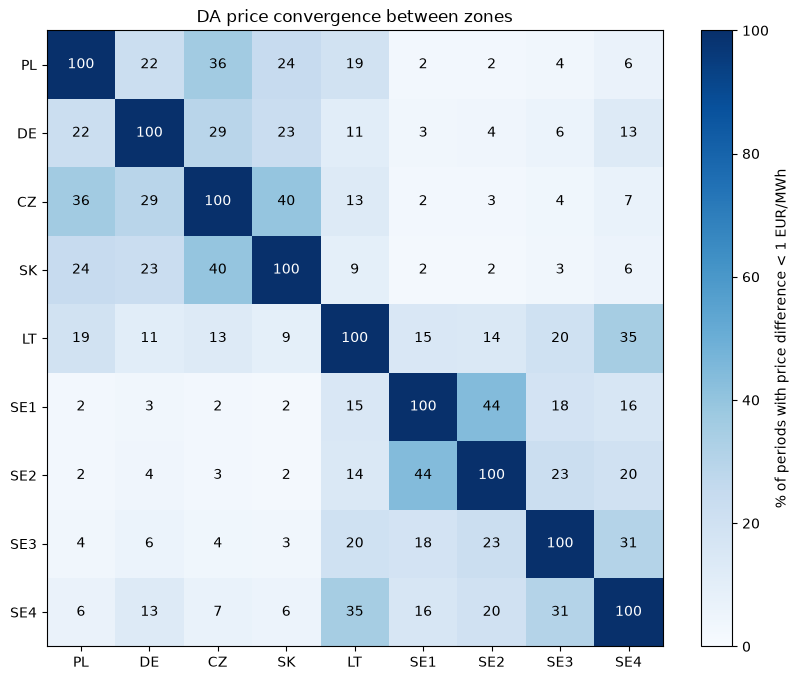

In [239]:
plt.figure(figsize=(10, 8))
plt.imshow(convergence.values, cmap="Blues", vmin=0, vmax=100)
plt.colorbar(label="% of periods with price difference < 1 EUR/MWh")
plt.xticks(range(len(zones)), zones)
plt.yticks(range(len(zones)), zones)

# numbers inside the squares
for i in range(len(zones)):
    for j in range(len(zones)):
        value = convergence.iloc[i, j]
        if value > 50:
            text_color = "white"
        else:
            text_color = "black"
        plt.text(j, i, round(value), ha="center", va="center", color=text_color)

plt.title("DA price convergence between zones")
plt.show()

## PL: cena a zapotrzebowanie rezydualne

In [240]:
pl_data = pd.DataFrame({
    "load": load_table["PL"],
    "wind": wind_table["PL"],
    "solar": solar_table["PL"],
})
pl_data["residual"] = pl_data["load"] - pl_data["wind"] - pl_data["solar"]
pl_data = pl_data.reset_index()

pl_price = prices[prices["zone"] == "PL"][["time", "price"]]
pl_data = pd.merge(pl_data, pl_price, on="time")
pl_data = pl_data.sort_values("time")
pl_data.head()

,time,load,wind,solar,residual,price
0,2025-01-02 00:00:00,14500.0,8537.0,0.0,5963.0,-8.43
1,2025-01-02 00:15:00,14500.0,8537.0,0.0,5963.0,-8.43
2,2025-01-02 00:30:00,14500.0,8537.0,0.0,5963.0,-8.43
3,2025-01-02 00:45:00,14500.0,8537.0,0.0,5963.0,-8.43
4,2025-01-02 01:00:00,14400.0,8594.0,0.0,5806.0,-21.04


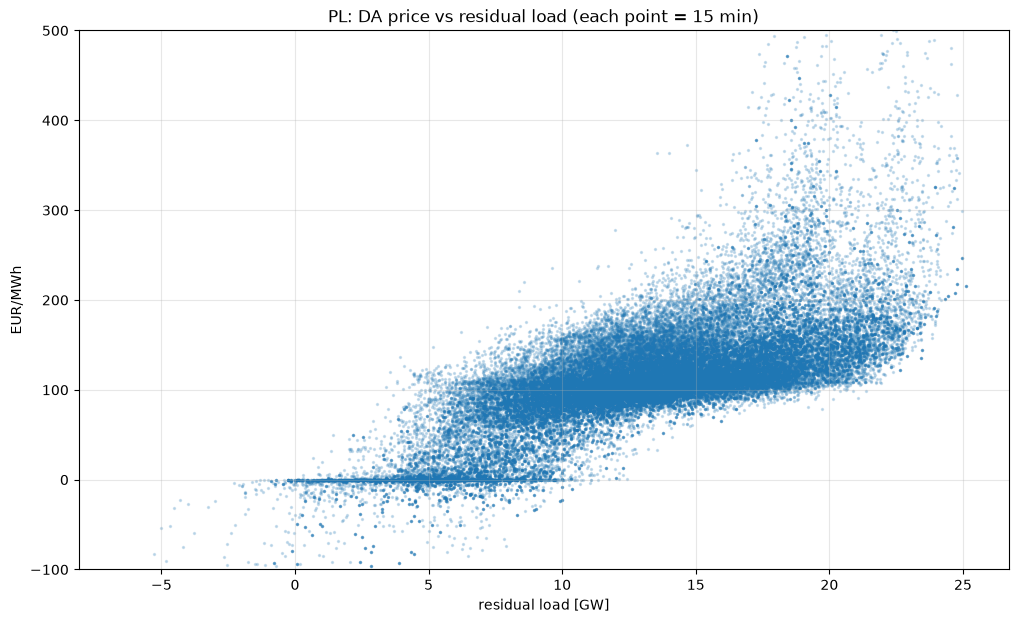

In [241]:
plt.figure(figsize=(12, 7))
plt.scatter(pl_data["residual"] / 1000, pl_data["price"], s=2, alpha=0.2)
plt.title("PL: DA price vs residual load (each point = 15 min)")
plt.xlabel("residual load [GW]")
plt.ylabel("EUR/MWh")
plt.ylim(-100, 500)
plt.grid(alpha=0.3)
plt.show()

In [242]:
# correlation: 1 = perfectly increasing relation, 0 = no relation
pl_data[["price", "residual", "load", "wind", "solar"]].corr()["price"].round(2)

price       1.00
residual    0.72
load        0.32
wind       -0.20
solar      -0.53
Name: price, dtype: float64

# 5. Kontrola danych

## Czy prognoza była dostępna przed zamknięciem aukcji DA?

Aukcja DA zamyka się o 12:00 czasu lokalnego dzień przed dostawą (D-1).
Prognoza nadaje się do backcastu tylko wtedy, gdy `published_at` jest **przed** tą godziną –
inaczej model dostaje informację, której uczestnicy rynku jeszcze nie mieli.

In [243]:
def gate_closure(times):
    # times: delivery start in UTC (no timezone in the object)
    # returns: 12:00 local time on the day before delivery, in UTC
    local_times = times.dt.tz_localize("UTC").dt.tz_convert("Europe/Warsaw")
    local_day = local_times.dt.normalize()
    gate = local_day - pd.Timedelta(days=1) + pd.Timedelta(hours=12)
    return gate.dt.tz_convert("UTC").dt.tz_localize(None)

In [244]:
load_fcst["published"] = pd.to_datetime(load_fcst["published_at"], utc=True).dt.tz_localize(None)
gen_fcst["published"] = pd.to_datetime(gen_fcst["published_at"], utc=True).dt.tz_localize(None)

# positive = published before gate closure (OK), negative = too late
load_fcst["hours before gate"] = (gate_closure(load_fcst["time"]) - load_fcst["published"]).dt.total_seconds() / 3600
gen_fcst["hours before gate"] = (gate_closure(gen_fcst["time"]) - gen_fcst["published"]).dt.total_seconds() / 3600

gen_fcst[["time", "zone", "fuel_type", "run_date", "published", "hours before gate"]].head()

,time,zone,fuel_type,run_date,published,hours before gate
0,2025-01-02,DE,wind,2025-01-01,2025-01-01 06:55:00,4.083333
1,2025-01-02,CZ,solar,2025-01-01,2025-01-01 06:55:00,4.083333
2,2025-01-02,PL,solar,2025-01-01,2025-01-01 06:55:00,4.083333
3,2025-01-02,DE,solar,2025-01-01,2025-01-01 06:55:00,4.083333
4,2025-01-02,PL,wind,2025-01-01,2025-01-01 06:55:00,4.083333


In [245]:
# share of records published before gate closure
gate_check = pd.DataFrame({
    "file": ["load", "wind + solar"],
    "before gate [%]": [
        (load_fcst["hours before gate"] >= 0).mean() * 100,
        (gen_fcst["hours before gate"] >= 0).mean() * 100,
    ],
    "median hours before gate": [
        load_fcst["hours before gate"].median(),
        gen_fcst["hours before gate"].median(),
    ],
})
gate_check.round(1)

,file,before gate [%],median hours before gate
0,load,100.0,3.1
1,wind + solar,100.0,3.1


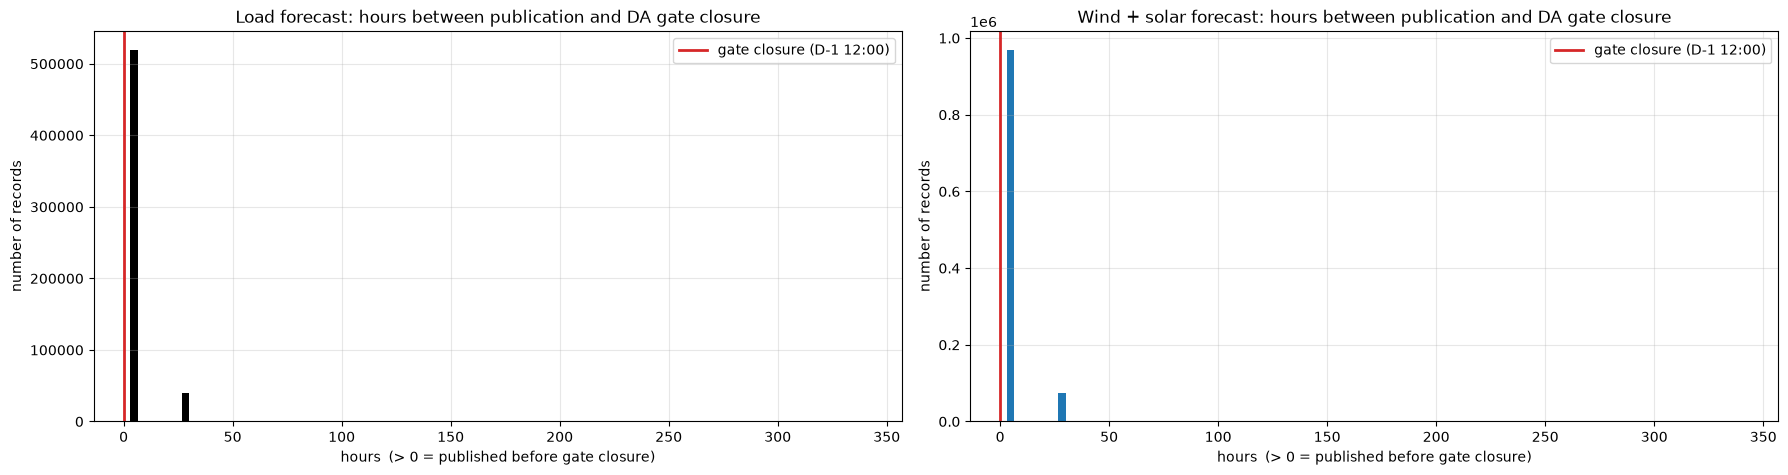

In [246]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

axes[0].hist(load_fcst["hours before gate"], bins=100, color="black")
axes[0].set_title("Load forecast: hours between publication and DA gate closure")

axes[1].hist(gen_fcst["hours before gate"], bins=100, color="tab:blue")
axes[1].set_title("Wind + solar forecast: hours between publication and DA gate closure")

for ax in axes:
    ax.axvline(0, color="tab:red", linewidth=2, label="gate closure (D-1 12:00)")
    ax.set_xlabel("hours  (> 0 = published before gate closure)")
    ax.set_ylabel("number of records")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

## Pokrycie danych: od kiedy do kiedy są dane dla każdej strefy

In [247]:
coverage = []

for zone in zones:
    sources = {
        "prices": prices[prices["zone"] == zone]["time"],
        "load": load_fcst[load_fcst["zone"] == zone]["time"],
        "wind": gen_fcst[(gen_fcst["zone"] == zone) & (gen_fcst["fuel_type"] == "wind")]["time"],
        "solar": gen_fcst[(gen_fcst["zone"] == zone) & (gen_fcst["fuel_type"] == "solar")]["time"],
    }
    for name, times in sources.items():
        if len(times) == 0:
            coverage.append({"zone": zone, "data": name, "range": "MISSING"})
        else:
            date_range = times.min().strftime("%Y-%m-%d") + " – " + times.max().strftime("%Y-%m-%d")
            coverage.append({"zone": zone, "data": name, "range": date_range})

coverage = pd.DataFrame(coverage)
coverage.pivot(index="zone", columns="data", values="range").loc[zones]

data,load,prices,solar,wind
zone,,,,
PL,2025-01-02 – 2026-11-12,2025-01-01 – 2026-10-27,2025-01-02 – 2026-11-12,2025-01-02 – 2026-11-12
DE,2025-01-02 – 2026-11-12,2025-01-01 – 2026-10-27,2025-01-02 – 2026-11-12,2025-01-02 – 2026-11-12
CZ,2025-01-02 – 2026-11-12,2025-01-01 – 2026-10-26,2025-01-02 – 2026-11-12,2025-01-02 – 2026-11-12
SK,2025-02-01 – 2026-11-12,2025-01-01 – 2026-10-26,2025-02-01 – 2026-11-12,MISSING
LT,2025-02-01 – 2026-11-12,2025-01-01 – 2026-10-27,2025-02-01 – 2026-11-12,2025-02-01 – 2026-11-12
SE1,2025-02-01 – 2026-11-12,2025-01-01 – 2026-10-27,2025-03-08 – 2026-11-12,2025-02-01 – 2026-11-12
SE2,2025-02-01 – 2026-11-12,2025-01-01 – 2026-10-27,2025-03-08 – 2026-11-12,2025-02-01 – 2026-11-12
SE3,2025-02-01 – 2026-11-12,2025-01-01 – 2026-10-27,2025-03-08 – 2026-11-12,2025-02-01 – 2026-11-12
SE4,2025-02-01 – 2026-11-12,2025-01-01 – 2026-10-27,2025-03-08 – 2026-11-12,2025-02-01 – 2026-11-12


# 6. Przepustowości połączeń do modelu (CSV dla PyPSA)

Jedna wartość na cały rok 2025, osobno dla każdego kierunku. Każdy kierunek to osobny `Link` w PyPSA.
- granice CORE (PL, DE, CZ, SK): 99. percentyl planowanej wymiany handlowej DA z `sce.csv`,
- łącza HVDC z SE4 (PL, LT, DE): mediana maxBex z pliku Nordic (w 2025 stała, równa mocy kabla),
- PL–LT (LitPol Link): 500 MW, moc znamionowa łącza (źródło w `docs/bibliografia.md`; w danych za 2025 brak tej granicy).

In [248]:
model_year = 2025

exchange_year = exchange_unique[exchange_unique["time"].dt.year == model_year]
nordic_year = nordic_bex[nordic_bex["time"].dt.year == model_year]

exchange_year.shape, nordic_year.shape

((625584, 5), (15390, 65))

In [249]:
# AC borders inside CORE: p99 of scheduled exchange, one row per direction
core_zones = ["PL", "DE", "CZ", "SK"]
capacity_rows = []

for zone_from in core_zones:
    for zone_to in core_zones:
        flows = exchange_year[(exchange_year["zone_from"] == zone_from) & (exchange_year["zone_to"] == zone_to)]["value"]
        # skip pairs that are not in the file (e.g. DE-SK, no common border)
        if len(flows) > 0:
            capacity_rows.append({
                "name": zone_from + "->" + zone_to,
                "bus0": zone_from,
                "bus1": zone_to,
                "p_nom": round(flows.quantile(0.99)),
                "source": "sce.csv " + str(model_year) + ", p99 of DA scheduled exchange",
            })

pd.DataFrame(capacity_rows)

,name,bus0,bus1,p_nom,source
0,PL->DE,PL,DE,1971,"sce.csv 2025, p99 of DA scheduled exchange"
1,PL->CZ,PL,CZ,1047,"sce.csv 2025, p99 of DA scheduled exchange"
2,PL->SK,PL,SK,1562,"sce.csv 2025, p99 of DA scheduled exchange"
3,DE->PL,DE,PL,1704,"sce.csv 2025, p99 of DA scheduled exchange"
4,DE->CZ,DE,CZ,1968,"sce.csv 2025, p99 of DA scheduled exchange"
5,CZ->PL,CZ,PL,1081,"sce.csv 2025, p99 of DA scheduled exchange"
6,CZ->DE,CZ,DE,1572,"sce.csv 2025, p99 of DA scheduled exchange"
7,CZ->SK,CZ,SK,1107,"sce.csv 2025, p99 of DA scheduled exchange"
8,SK->PL,SK,PL,708,"sce.csv 2025, p99 of DA scheduled exchange"
9,SK->CZ,SK,CZ,607,"sce.csv 2025, p99 of DA scheduled exchange"


In [250]:
# HVDC links with SE4: median maxBex in the model year
hvdc_links = {
    "SE4->PL": ["SE4", "PL", "border_SE4_PL"],
    "PL->SE4": ["PL", "SE4", "border_PL_SE4"],
    "SE4->LT": ["SE4", "LT", "border_SE4_LT"],
    "LT->SE4": ["LT", "SE4", "border_LT_SE4"],
    "SE4->DE": ["SE4", "DE", "border_SE4_DE"],
    "DE->SE4": ["DE", "SE4", "border_DE_SE4"],
}

for name, info in hvdc_links.items():
    capacity_rows.append({
        "name": name,
        "bus0": info[0],
        "bus1": info[1],
        "p_nom": round(nordic_year[info[2]].median()),
        "source": "nordic_max_bex.csv " + str(model_year) + ", median maxBex",
    })

# PL-LT (LitPol Link): no data for 2025, rated capacity of the link
capacity_rows.append({"name": "PL->LT", "bus0": "PL", "bus1": "LT", "p_nom": 500, "source": "LitPol Link rated capacity (Wikipedia)"})
capacity_rows.append({"name": "LT->PL", "bus0": "LT", "bus1": "PL", "p_nom": 500, "source": "LitPol Link rated capacity (Wikipedia)"})

In [251]:
capacities = pd.DataFrame(capacity_rows).set_index("name")
capacities

,bus0,bus1,p_nom,source
name,,,,
PL->DE,PL,DE,1971,"sce.csv 2025, p99 of DA scheduled exchange"
PL->CZ,PL,CZ,1047,"sce.csv 2025, p99 of DA scheduled exchange"
PL->SK,PL,SK,1562,"sce.csv 2025, p99 of DA scheduled exchange"
DE->PL,DE,PL,1704,"sce.csv 2025, p99 of DA scheduled exchange"
DE->CZ,DE,CZ,1968,"sce.csv 2025, p99 of DA scheduled exchange"
CZ->PL,CZ,PL,1081,"sce.csv 2025, p99 of DA scheduled exchange"
CZ->DE,CZ,DE,1572,"sce.csv 2025, p99 of DA scheduled exchange"
CZ->SK,CZ,SK,1107,"sce.csv 2025, p99 of DA scheduled exchange"
SK->PL,SK,PL,708,"sce.csv 2025, p99 of DA scheduled exchange"


In [252]:
capacities.to_csv("../data/links/ntc_" + str(model_year) + ".csv")
print("saved:", len(capacities), "links")

saved: 18 links


Wczytanie w PyPSA (gdy będzie zainstalowane). Każdy wiersz to jednokierunkowy `Link` z limitem `p_nom` [MW]:

```python
links = pd.read_csv("../data/links/ntc_2025.csv", index_col="name")
n.add("Link", links.index, bus0=links["bus0"], bus1=links["bus1"], p_nom=links["p_nom"], efficiency=1.0)
```

Kolumna `source` jest tylko opisem i nie trafia do PyPSA. Nazwy `bus0` / `bus1` to nazwy stref (`PL`, `DE`, `CZ`, `SK`, `LT`, `SE4`),
więc węzły (`Bus`) w sieci muszą mieć dokładnie takie nazwy.

## 7. Emisyjność

In [253]:
emission_rate=pd.DataFrame({
    "fuel": ["hard coal", "lignite", "gas", "oil", "biomass", "hydro", "nuclear", "pumped storage", "battery"],
    "emission [kg/GJ]": [94.84, 110.71, 55.7, 76.86, 0.00, 0.0, 0.0, 0.0, 0.0]
})

## 8. Ceny

In [254]:
ara=pd.read_csv("../data/prices/Dane historyczne dla Coal (API2) CIF ARA (ARGUS-McCloskey) Futures.csv", usecols=["Date", "Price"])
ttf=pd.read_csv("../data/prices/ICE Dutch TTF Natural Gas Futures Historical Data.csv", usecols=["Date", "Price"])
ets=pd.read_csv("../data/prices/Carbon Emissions Futures Historical Data.csv", usecols=["Date", "Price"])
oil=pd.read_csv("../data/prices/ICE_crude_oil.csv", usecols=["Date", "Price"])
eur_usd=pd.read_csv("../data/prices/EUR_USD Historical Data.csv", usecols=["Date", "Price"])


In [255]:
def convert_to_datetime(df):
    df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
    df = df.sort_values("Date").set_index("Date").asfreq("D")
    df["Price"] = df["Price"].ffill()
    return df

In [256]:
ara,ttf, ets,oil,eur_usd = convert_to_datetime(ara), convert_to_datetime(ttf), convert_to_datetime(ets), convert_to_datetime(oil), convert_to_datetime(eur_usd)

In [257]:
oil

,Price
Date,
2024-12-31,74.38
2025-01-01,74.38
2025-01-02,74.38
2025-01-03,74.38
2025-01-04,74.38
...,...
2026-10-29,103.51
2026-10-30,103.51
2026-10-31,103.51


In [258]:
oil["Price"]=0
ara["usd/GJ"]=ara["Price"]/25.1
oil["usd/GJ"]=oil["Price"]/6.12
ttf["eur/GJ"]=ttf["Price"]/3.6


In [259]:
eur_usd=eur_usd.merge(ara, left_index=True, right_index=True, how="left", suffixes=("", "_ara")).merge(oil, left_index=True, right_index=True, how="left", suffixes=("", "_oil"))

In [260]:
eur_usd["ara eur/GJ"]=eur_usd["usd/GJ"]/eur_usd["Price"]
eur_usd["oil eur/GJ"]=eur_usd["usd/GJ_oil"]/eur_usd["Price"]

Text(0.5, 1.0, 'Fuel prices in EUR/GJ')

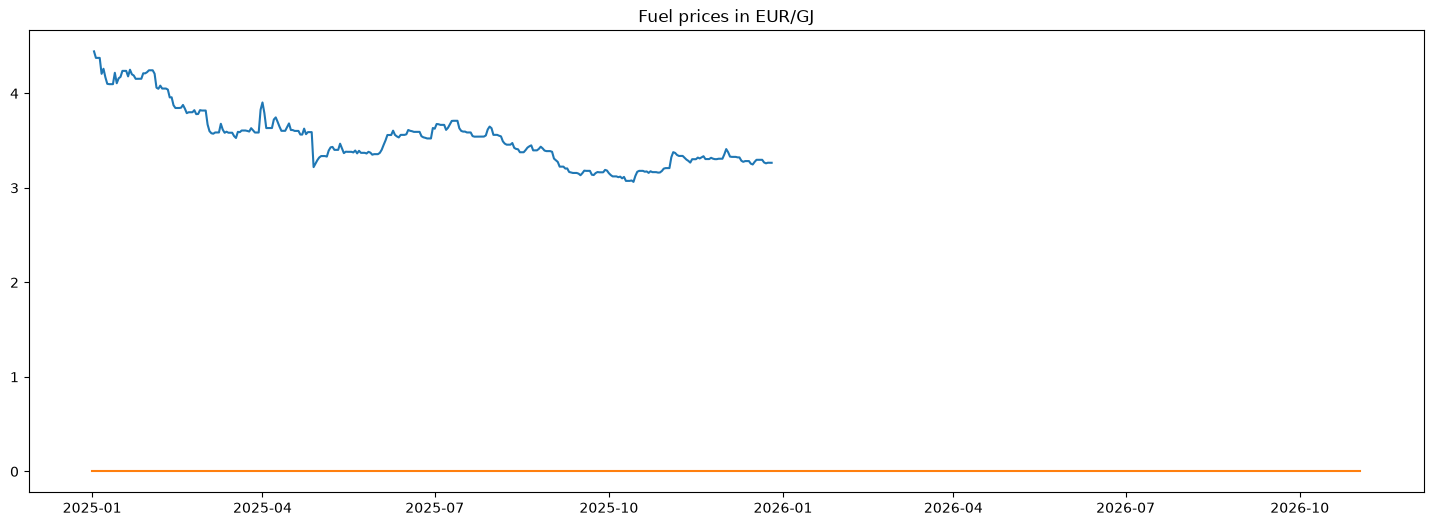

In [261]:
plt.figure(figsize=(18, 6))
plt.plot(eur_usd.index, eur_usd["ara eur/GJ"], label="Coal (API2) CIF ARA", color="tab:blue")
plt.plot(eur_usd.index, eur_usd["oil eur/GJ"], label="Crude oil (Brent)", color="tab:orange")
plt.title("Fuel prices in EUR/GJ")

In [262]:
fuel_prices=oil.merge(ara, left_index=True, right_index=True, how="left", suffixes=("", "_ara")).merge(
    ttf, left_index=True, right_index=True, how="left", suffixes=("", "_ttf")).merge(
        oil, left_index=True, right_index=True, how="left", suffixes=("", "_oil")).merge(
            ets, left_index=True, right_index=True, how="left", suffixes=("", "_ets"))

In [265]:
fuel_prices.to_csv("../data/prices/fuel_prices_2025.csv")